# 08 · Your first learned segmentation model

**Prerequisites:** you can write Python and NumPy code; complete lessons 01 and 07 first.
**Learning time:** 60–90 minutes. Default execution is a small offline run; no GPU is required.

You will turn an RGB image into a class label at every pixel, write a `Dataset`, train a small CNN, and inspect its errors. This is **semantic segmentation**: two disks share one class, even if they are different objects.

**Success check:** explain the shapes `[N,3,H,W] → [N,K,H,W] → [N,H,W]`, distinguish logits from labels, and improve held-out IoU over an all-background baseline.

Run each cell, predict its output first, then change one thing. These deliberately simple colored shapes teach the training mechanics; good scores here do not demonstrate real-world segmentation ability.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


In [2]:
import copy
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from learning.data import make_scene, make_dataset, show_triplet, palette_mask
from learning.torch_models import ArrayDataset, PixelCNN, TinyUNet
from learning.torch_models import run_epoch, confusion_matrix, iou_from_confusion

SEED = 42
FAST_RUN = True  # False increases training; keep True for your first Run All.
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("All DataLoaders use num_workers=0 for a simple Windows notebook workflow.")


PyTorch: 2.11.0+cu128 | device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
All DataLoaders use num_workers=0 for a simple Windows notebook workflow.


## 1. Make examples with known answers

The generator returns images in `[0,1]` and integer masks: `0=background`, `1=disk`, `2=rectangle`. An image contains visual evidence; its mask contains the answer supplied during supervised training. We split **whole images**, so pixels from one scene cannot leak between train and validation.


images: (48, 48, 48, 3) float32 masks: (48, 48, 48) uint8


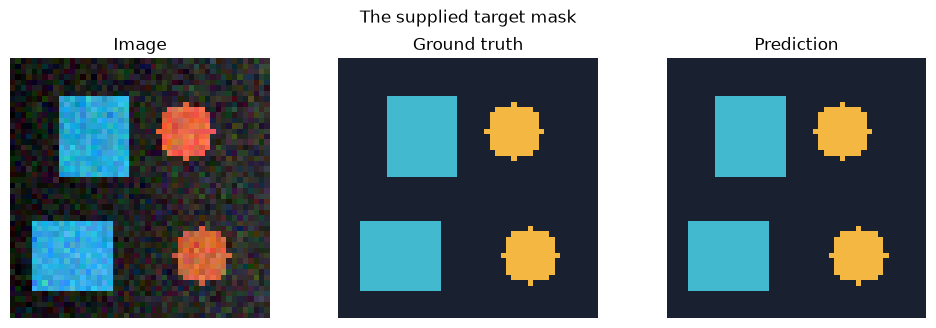

In [3]:
images, masks = make_dataset(n=48 if FAST_RUN else 240, size=48, seed=SEED)
order = np.random.default_rng(SEED).permutation(len(images))
cut = int(0.75 * len(images))
train_ids, val_ids = order[:cut], order[cut:]
assert set(train_ids).isdisjoint(val_ids)
print("images:", images.shape, images.dtype, "masks:", masks.shape, masks.dtype)
show_triplet(images[0], masks[0], masks[0], title="The supplied target mask");
plt.show()


## 2. Learn the tensor contract

NumPy images often put RGB last (`HWC`). PyTorch convolution layers expect channels first (`CHW`) and a batch dimension (`NCHW`). A target for multiclass cross-entropy is a `long` integer tensor, **without a channel dimension**. Do not normalize class IDs or divide masks by 255.

`permute` reorders axes; it does not rescale values. `argmax(dim=1)` will later select a class, not an x/y coordinate.


In [4]:
one_image = torch.from_numpy(images[0]).permute(2, 0, 1).float()
one_mask = torch.from_numpy(masks[0].astype(np.int64))
print("one image:", one_image.shape, one_image.dtype)
print("one mask:", one_mask.shape, one_mask.dtype)
assert one_image.shape == (3, 48, 48)
assert one_mask.shape == (48, 48) and one_mask.dtype == torch.long
assert set(one_mask.unique().tolist()) <= {0, 1, 2}


one image: torch.Size([3, 48, 48]) torch.float32
one mask: torch.Size([48, 48]) torch.int64


## 3. Separate one sample from a batch

A `Dataset` answers “what are image and target number i?” A `DataLoader` groups samples and optionally shuffles their order. Shuffle training data; keep validation stable. Use `num_workers=0` while learning on Windows to avoid notebook multiprocessing surprises.


In [5]:
class ShapeDataset(Dataset):
    def __init__(self, rgb_images, label_masks):
        self.images, self.masks = rgb_images, label_masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        x = torch.from_numpy(self.images[index].transpose(2, 0, 1).copy()).float()
        y = torch.from_numpy(self.masks[index].astype(np.int64))
        return x, y

train_loader = DataLoader(ShapeDataset(images[train_ids], masks[train_ids]),
                          batch_size=6, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(ShapeDataset(images[val_ids], masks[val_ids]),
                        batch_size=6, shuffle=False, num_workers=0)
xb, yb = next(iter(train_loader))
print("batch image:", xb.shape, "batch target:", yb.shape)


batch image: torch.Size([6, 3, 48, 48]) batch target: torch.Size([6, 48, 48])


## 4. A CNN predicts one score per class per pixel

The `3×3` convolutions combine nearby RGB values. Padding keeps height and width unchanged. The final `1×1` convolution mixes features into three output scores called **logits**. We use no pooling here; lesson 09 adds an encoder, decoder, and skip connections.

This baseline has a small receptive field. Because shape colors are informative, it can succeed without truly understanding shape.


In [6]:
class FirstSegmentationCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 12, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(12, 12, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(12, 3, kernel_size=1),
        )

    def forward(self, x):
        return self.layers(x)

model = FirstSegmentationCNN().to(DEVICE)
logits = model(xb.to(DEVICE))
assert logits.shape == (len(xb), 3, 48, 48)
print("logits:", logits.shape, "parameters:", sum(p.numel() for p in model.parameters()))


logits: torch.Size([6, 3, 48, 48]) parameters: 1683


## 5. Turn scores into a loss, probabilities, and labels

These are three different operations. Cross-entropy compares **raw logits** with integer targets and internally performs the stable log-softmax calculation. Softmax produces probabilities for inspection. Argmax produces the discrete class map. Argmax is not differentiable, so do not use an argmax mask as the training loss input.


In [7]:
criterion = nn.CrossEntropyLoss()
initial_loss = criterion(logits, yb.to(DEVICE))
probabilities = logits.softmax(dim=1)
predicted_mask = logits.argmax(dim=1)
assert torch.allclose(probabilities.sum(1), torch.ones_like(probabilities[:, 0]), atol=1e-6)
print("initial loss:", round(initial_loss.item(), 4))
print("probabilities:", probabilities.shape, "prediction:", predicted_mask.shape)
print("one pixel's probabilities:", probabilities[0, :, 20, 20].detach().cpu().numpy())


initial loss: 1.1889
probabilities: torch.Size([6, 3, 48, 48]) prediction: torch.Size([6, 48, 48])
one pixel's probabilities: [0.28976974 0.312848   0.3973823 ]


## 6. Train: forward → loss → zero gradients → backward → update

Adam updates parameters using gradients. Gradients accumulate unless cleared. `model.train()` activates training behavior; `model.eval()` selects inference behavior for layers such as dropout or batch normalization. This tiny model has neither, but use the correct pattern from the beginning.

We record validation loss and IoU after every epoch. Validation guides experiments; it is not a final untouched test set.


In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 8 if FAST_RUN else 40
history = []
for epoch in range(epochs):
    model.train()
    total, count = 0.0, 0
    for batch_images, batch_masks in train_loader:
        batch_images, batch_masks = batch_images.to(DEVICE), batch_masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        output = model(batch_images)
        loss = criterion(output, batch_masks)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(batch_images)
        count += len(batch_images)
    validation = run_epoch(model, val_loader, criterion, classes=3)
    history.append((total / count, validation["loss"], validation["miou"]))
    print(f"epoch {epoch+1:02d} | train CE {total/count:.3f} | val CE {validation['loss']:.3f} | val mIoU {validation['miou']:.3f}")


C:\Users\Hareram ray\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


epoch 01 | train CE 1.080 | val CE 0.871 | val mIoU 0.563
epoch 02 | train CE 0.649 | val CE 0.342 | val mIoU 0.850
epoch 03 | train CE 0.201 | val CE 0.077 | val mIoU 0.961
epoch 04 | train CE 0.051 | val CE 0.035 | val mIoU 0.960
epoch 05 | train CE 0.025 | val CE 0.019 | val mIoU 0.975
epoch 06 | train CE 0.016 | val CE 0.015 | val mIoU 0.978
epoch 07 | train CE 0.013 | val CE 0.013 | val mIoU 0.983
epoch 08 | train CE 0.012 | val CE 0.010 | val mIoU 0.985


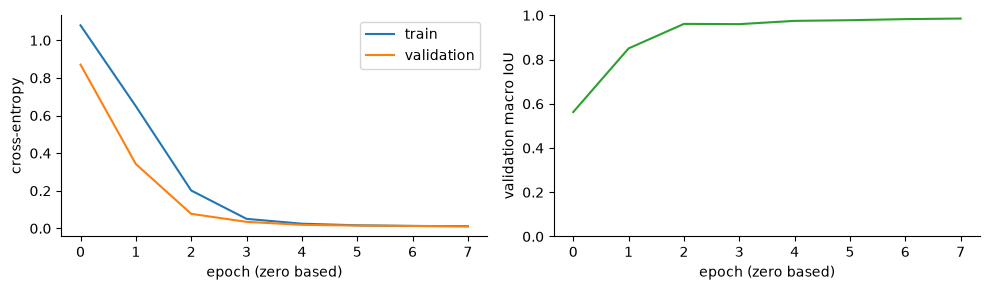

In [9]:
history = np.asarray(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(history[:, 0], label="train"); axes[0].plot(history[:, 1], label="validation")
axes[0].set(xlabel="epoch (zero based)", ylabel="cross-entropy"); axes[0].legend()
axes[1].plot(history[:, 2], color="tab:green")
axes[1].set(xlabel="epoch (zero based)", ylabel="validation macro IoU", ylim=(0, 1))
plt.tight_layout(); plt.show()


## 7. Inspect failures, not just a mean score

`inference_mode()` prevents gradient recording during prediction. Macro IoU gives each present class equal weight; pixel accuracy can hide small foreground failures. Our helper aggregates a confusion matrix over all validation pixels before computing per-class IoU. A class absent from truth **and** prediction is excluded as undefined.


background-only per-class IoU: [0.786 0.    0.   ]
trained per-class IoU: [0.995 0.966 0.994]


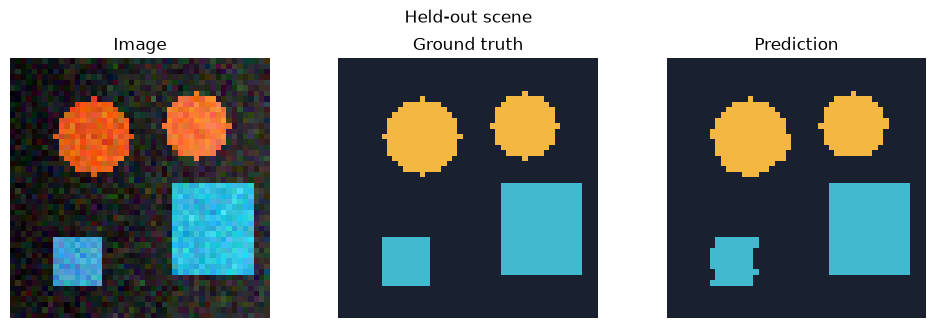

In [10]:
model.eval()
with torch.inference_mode():
    val_tensor = torch.from_numpy(images[val_ids].transpose(0, 3, 1, 2)).to(DEVICE)
    predictions = model(val_tensor).argmax(1).cpu().numpy()
truth = torch.from_numpy(masks[val_ids].astype(np.int64))
baseline_cm = confusion_matrix(torch.zeros_like(truth), truth, 3)
print("background-only per-class IoU:", iou_from_confusion(baseline_cm).numpy().round(3))
print("trained per-class IoU:", validation["iou"].round(3))
show_triplet(images[val_ids[0]], masks[val_ids[0]], predictions[0], title="Held-out scene")
plt.show()


## Experiment 1 · Read a different pixel

Before running: if logits are `[N,3,H,W]`, what shape do probabilities for one pixel have? Change `(row, col)` to a background pixel and a disk pixel. Observe whether high probability corresponds to correctness.


In [11]:
row, col = 20, 20
with torch.inference_mode():
    pixel_p = model(val_tensor[:1]).softmax(1)[0, :, row, col].cpu().numpy()
print("p(background, disk, rectangle):", pixel_p.round(3))
print("true class:", masks[val_ids[0], row, col], "predicted:", pixel_p.argmax())


p(background, disk, rectangle): [0.999 0.001 0.   ]
true class: 0 predicted: 0


<details><summary>Worked solution 1</summary>

The shape is `(3,)`. Use `p = model(val_tensor[:1]).softmax(1)[0, :, row, col]`. The class probabilities sum to one. A confident wrong answer is possible; softmax is not a guarantee of correctness. Coordinates index `[row, column]`, not `[x, y]`.
</details>

## Experiment 2 · Remove spatial context

Replace **both** `3×3` layers with `kernel_size=1, padding=0`. Recreate the model and optimizer, then rerun training. Record per-class IoU, not only loss. Does this dataset really require spatial reasoning?


In [12]:
# Working starting point for your ablation; training is intentionally your task.
color_only = nn.Sequential(nn.Conv2d(3, 12, 1), nn.ReLU(),
                           nn.Conv2d(12, 12, 1), nn.ReLU(), nn.Conv2d(12, 3, 1)).to(DEVICE)
print("color-only output shape:", tuple(color_only(xb.to(DEVICE)).shape))


color-only output shape: (6, 3, 48, 48)


<details><summary>Worked solution 2</summary>

Create `optimizer_color = torch.optim.Adam(color_only.parameters(), lr=0.01)` and run `run_epoch(color_only, train_loader, criterion, optimizer_color)` for the same number of epochs. Evaluate with `run_epoch(color_only, val_loader, criterion)`. A `1×1` network classifies each pixel independently. Strong results would expose how easy color cues make this dataset; they would not prove shape understanding.
</details>

## Experiment 3 · Cause a controlled failure

Repeat the experiment with `make_dataset(..., noise=0.20)` and the same train/validation procedure. Predict what should happen to boundary errors. Keep the validation set fixed when comparing architectures.


<details><summary>Worked solution 3</summary>

Generate noisy scenes with a separate fixed seed, convert them to `ArrayDataset`, and evaluate the existing model. This measures robustness without retraining. Then train a fresh model with noisy training data and compare on the **same** noisy validation scenes. Do not claim the noise helped from different validation sets. Expect more ambiguity, but measure rather than assume.
</details>

## Checkpoint and common errors

- Explain why the target has no RGB channel and why it uses `torch.long`.
- If the loss reports a shape mismatch, print **both** logits and targets immediately before the loss.
- If a class is out of bounds, inspect `np.unique(masks)` and the number of output channels.
- If validation still builds graphs, use `inference_mode()` or `no_grad()`.
- If CUDA is unavailable, this lesson runs on CPU; an NVIDIA GPU also needs a CUDA-enabled PyTorch installation.
- Before moving on, explain why more training cannot fix incorrect labels or image/mask misalignment.


## References and next step

- [PyTorch cross-entropy contract](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [PyTorch Dataset and DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [PyTorch training loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)

Continue with **09_unet_training.ipynb**: recover fine details using skip connections, separate train/validation/test, and save the best model.
